In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("smart_manufacturing_data.csv")

In [3]:
df

,timestamp,machine_id,temperature,vibration,humidity,pressure,energy_consumption,machine_status,anomaly_flag,predicted_remaining_life,failure_type,downtime_risk,maintenance_required
0,2025-01-01 00:00:00,39,78.61,28.65,79.96,3.73,2.16,1,0,106,Normal,0.0,0
1,2025-01-01 00:01:00,29,68.19,57.28,35.94,3.64,0.69,1,0,320,Normal,0.0,0
2,2025-01-01 00:02:00,15,98.94,50.20,72.06,1.00,2.49,1,1,19,Normal,1.0,1
3,2025-01-01 00:03:00,43,90.91,37.65,30.34,3.15,4.96,1,1,10,Normal,1.0,1
4,2025-01-01 00:04:00,8,72.32,40.69,56.71,2.68,0.63,2,0,65,Vibration Issue,0.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,2025-03-11 10:35:00,3,71.47,54.34,46.72,1.83,3.05,1,0,313,Normal,0.0,0
99996,2025-03-11 10:36:00,23,87.23,34.99,33.84,4.67,4.47,1,0,439,Normal,0.0,0
99997,2025-03-11 10:37:00,10,93.01,51.79,64.28,4.04,3.62,1,1,30,Normal,1.0,1
99998,2025-03-11 10:38:00,47,84.41,22.35,35.18,2.88,2.37,1,0,487,Normal,0.0,0


In [4]:
print("Dataset shape:", df.shape)
print("\nData types:\n", df.dtypes)
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

print("\nFailure categories:")
print(df["failure_type"].value_counts())

print("\nAnomaly flag:")
print(df["anomaly_flag"].value_counts())

print("\nMaintenance required:")
print(df["maintenance_required"].value_counts())

Dataset shape: (100000, 13)

Data types:
 timestamp                    object
machine_id                    int64
temperature                 float64
vibration                   float64
humidity                    float64
pressure                    float64
energy_consumption          float64
machine_status                int64
anomaly_flag                  int64
predicted_remaining_life      int64
failure_type                 object
downtime_risk               float64
maintenance_required          int64
dtype: object

Missing values:
 timestamp                   0
machine_id                  0
temperature                 0
vibration                   0
humidity                    0
pressure                    0
energy_consumption          0
machine_status              0
anomaly_flag                0
predicted_remaining_life    0
failure_type                0
downtime_risk               0
maintenance_required        0
dtype: int64

Duplicate rows: 0

Failure categories:
failure_type
No

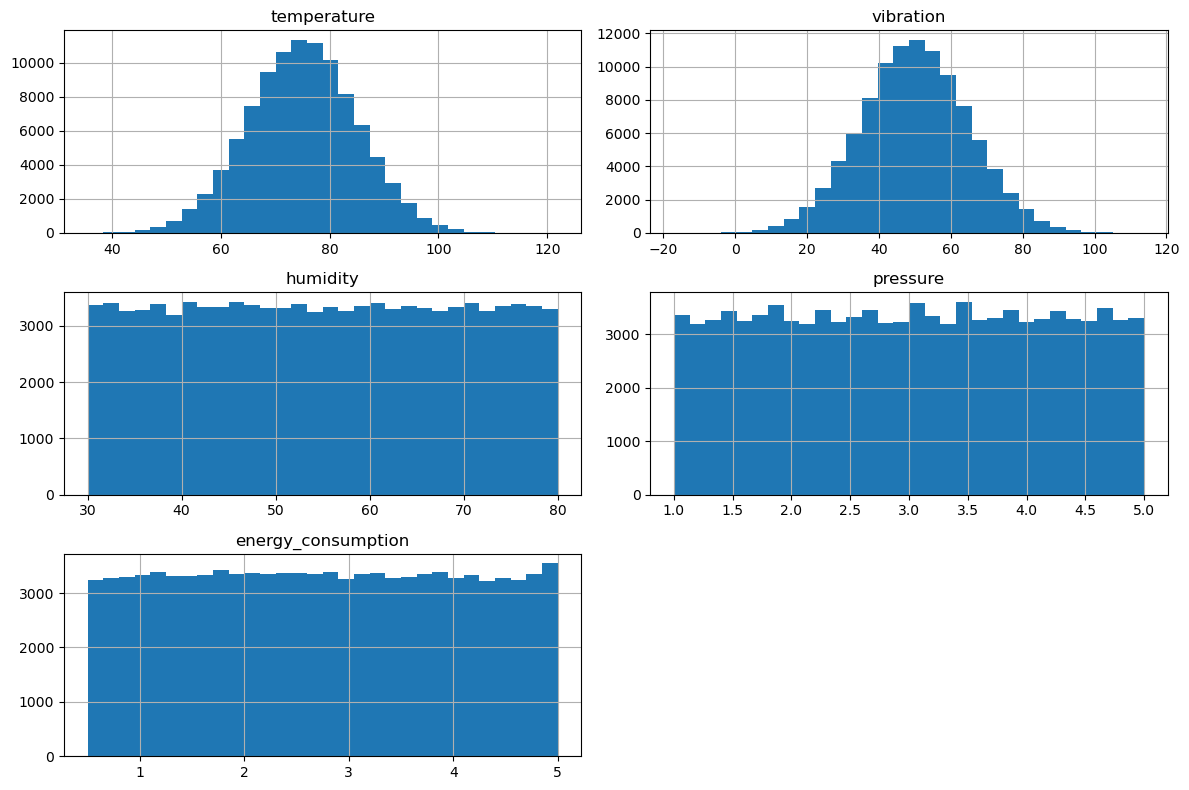

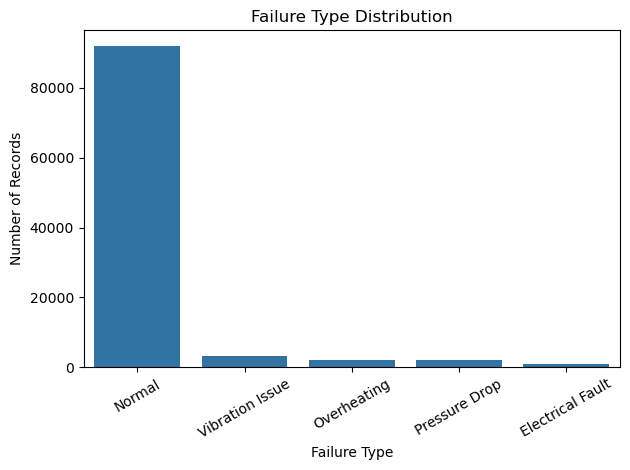

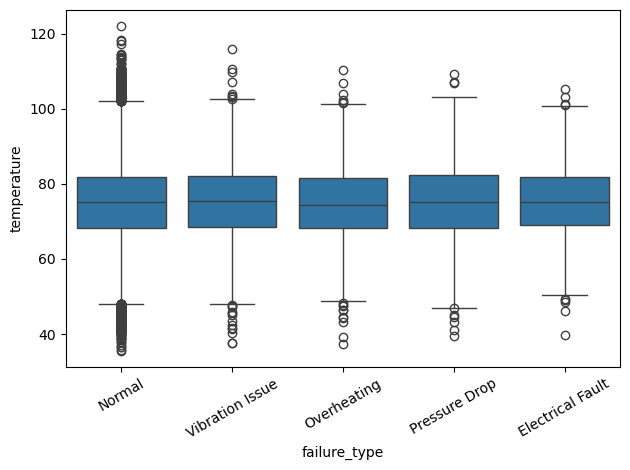

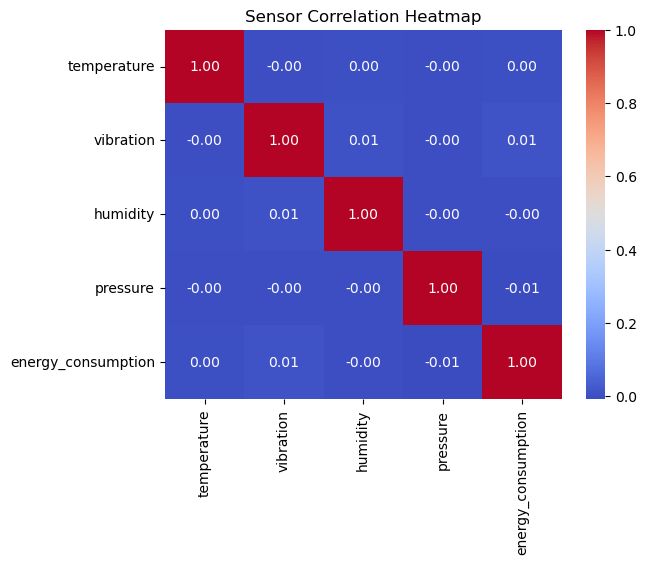

In [5]:
import seaborn as sns

sensor_cols = [
    "temperature", "vibration", "humidity",
    "pressure", "energy_consumption"
]

df[sensor_cols].hist(
    figsize=(12, 8), bins=30
)
plt.tight_layout()
plt.show()

failure_counts = df["failure_type"].value_counts()

sns.barplot(
    x=failure_counts.index,
    y=failure_counts.values
)

plt.xticks(rotation=30)
plt.title("Failure Type Distribution")
plt.xlabel("Failure Type")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()
sns.boxplot(
    data=df, x="failure_type", y="temperature"
)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

sns.heatmap(
    df[sensor_cols].corr(),
    annot=True, cmap="coolwarm", fmt=".2f"
)
plt.title("Sensor Correlation Heatmap")
plt.show()


In [7]:
# Calculate Q1 and Q3 separately for each failure type
Q1 = df.groupby("failure_type")["temperature"].transform(
    lambda x: x.quantile(0.25)
)

Q3 = df.groupby("failure_type")["temperature"].transform(
    lambda x: x.quantile(0.75)
)

# Calculate IQR
IQR = Q3 - Q1

# Calculate lower and upper limits
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

# Identify outliers
outliers = (
    (df["temperature"] < lower_limit) |
    (df["temperature"] > upper_limit)
)

print("Number of outliers:", outliers.sum())

# Remove outlier rows while keeping missing temperatures unchanged
df = df.loc[~outliers].copy()

print("Dataset shape after removing outliers:", df.shape)

Number of outliers: 55
Dataset shape after removing outliers: (99194, 13)


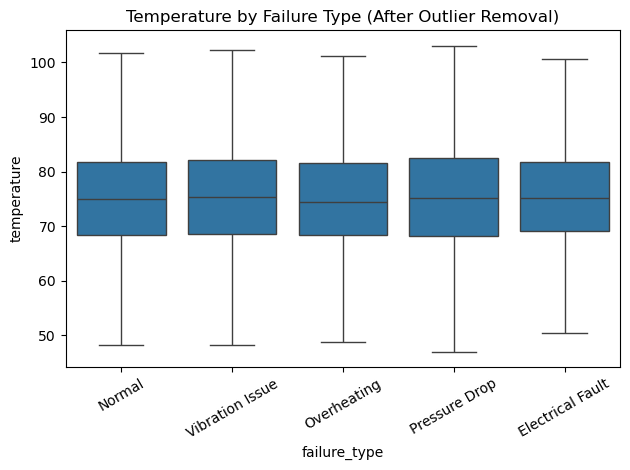

In [8]:
#After removing outliers

sns.boxplot(
    data=df, x="failure_type", y="temperature"
)

plt.xticks(rotation=30)
plt.title("Temperature by Failure Type (After Outlier Removal)")
plt.tight_layout()
plt.show()